# 02 — Pré-processamento do PTB-XL v1.0.3

**DCA3606 — Inteligência Artificial (UFRN).** Este notebook prepara sinais e alvos para classificação Normal × Alterado e regressão da idade. Não treina modelos nem escolhe hiperparâmetros.

Execute a partir da raiz do projeto. Dependências: `numpy`, `pandas`, `matplotlib`, `wfdb`, `ipykernel`. O módulo `src/preprocessamento.py` contém a lógica reutilizável; o notebook apresenta critérios, resultados, validações e exemplos visuais. Os arquivos originais permanecem intactos.

## 1. Critérios herdados da EDA

Somente códigos SCP com `diagnostic == 1` entram nas cinco superclasses. **Classe 0:** NORM sem MI, STTC, CD ou HYP. **Classe 1:** ao menos uma de MI, STTC, CD ou HYP sem NORM. Casos mistos ou sem superclasse reconhecida ficam fora da classificação. A regressão aceita idade numérica finita maior que zero e menor que 300; `300` é anonimização. O mesmo ECG pode participar de uma ou ambas as tarefas. As entradas são exclusivamente as 12 derivações do ECG; idade e diagnósticos ficam apenas nos metadados de alvo.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from IPython.display import display
from src.preprocessamento import (
    localizar_dataset, construir_metadados, preparar_ptbxl,
    validar_preparacao, abrir_sinais, DERIVACOES
)

RAIZ = Path.cwd()
DADOS = localizar_dataset(RAIZ)
SAIDA = RAIZ / 'resultados' / 'preprocessamento'
SAIDA.mkdir(parents=True, exist_ok=True)
SEMENTE = 3606
print('Dataset:', DADOS.relative_to(RAIZ))
print('Saída:', SAIDA.relative_to(RAIZ))
print('Bibliotecas:', {'numpy': np.__version__, 'pandas': pd.__version__,
                       'matplotlib': plt.matplotlib.__version__, 'wfdb': wfdb.__version__})

metadados_eda = construir_metadados(DADOS)
print('Total:', len(metadados_eda))
display(metadados_eda.motivo_classificacao.value_counts().rename('ECGs').to_frame())
display(metadados_eda.motivo_regressao.value_counts().rename('ECGs').to_frame())
print('Elegíveis para ambas antes da auditoria de sinais:',
      int((metadados_eda.alvo_classificacao.notna() & metadados_eda.alvo_idade.notna()).sum()))

Dataset: ptb-xl-1.0.3/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
Saída: resultados/preprocessamento
Bibliotecas: {'numpy': '2.5.5', 'pandas': '3.1.1', 'matplotlib': '3.11.2', 'wfdb': '4.3.1'}


Total: 21799


,ECGs
motivo_classificacao,
alterado,11874
normal,9069
ambiguo_norm_e_alteracao,445
sem_superclasse_diagnostica,411


,ECGs
motivo_regressao,
idade_valida,21506
idade_300_anonimizada,293


Elegíveis para ambas antes da auditoria de sinais: 20659


## 2. Auditoria integral e normalização

O módulo lê **um ECG por vez** com WFDB. Exige 1.000 amostras, 12 derivações na ordem esperada, 100 Hz, unidade mV, valores finitos e nenhuma derivação exatamente constante. Registra por exame causas de rejeição. Amplitude absoluta de **5 mV ou mais** gera um **alerta para inspeção**, sem exclusão automática; esse limiar de triagem é fixado antes da leitura e não é escolhido a partir da validação ou do teste.

Cada sinal aprovado é gravado uma única vez em um arquivo `float32` de formato `(N, 1000, 12)`. Os CSVs de classificação e regressão apontam para linhas desse arquivo. Isso evita cópias grandes por tarefa ou arquitetura.

Para cada derivação `c`, a normalização é

$$\mu_c=\frac{1}{N_{tr}\,T}\sum_{i\in treino}\sum_{t=1}^{T}x_{itc},\qquad
\sigma_c=\sqrt{\frac{1}{N_{tr}\,T}\sum_{i\in treino}\sum_t x_{itc}^2-\mu_c^2},\qquad
z_{itc}=\frac{x_{itc}-\mu_c}{\sigma_c}.$$

A média e o desvio são calculados **somente** na união dos ECGs elegíveis dos folds 1–8 com sinal aprovado. Os mesmos 12 pares de parâmetros são aplicados aos folds 9 e 10. A transformação preserva ordem temporal, número de canais e diferenças relativas de amplitude dentro de cada derivação; não centraliza nem reescala cada ECG isoladamente. Os parâmetros são salvos em `normalizacao.json`.

In [2]:
resumo = preparar_ptbxl(RAIZ, SAIDA, limiar_alerta_mv=5.0, lote_normalizacao=128)
print('Auditoria e preparação concluídas.')
display(pd.DataFrame([{
    'originais': resumo['ecgs_originais'],
    'inspecionados': resumo['candidatos_a_inspecao'],
    'sinais aprovados': resumo['sinais_aprovados'],
    'sinais rejeitados': resumo['sinais_rejeitados'],
    'alertas de amplitude': resumo['alertas_amplitude_extrema'],
    'classificação': resumo['classificacao']['total'],
    'regressão': resumo['regressao']['total'],
    'ambas': resumo['ambas']
}]))

Auditoria e preparação concluídas.


,originais,inspecionados,sinais aprovados,sinais rejeitados,alertas de amplitude,classificação,regressão,ambas
0,21799,21790,21789,1,305,20942,21505,20658


## 3. Contagens, qualidade e parâmetros persistidos

As tabelas a seguir vêm dos arquivos realmente produzidos. `qualidade_sinais.csv` registra cada ECG inspecionado, inclusive rejeições e alertas. Os motivos de inelegibilidade dos alvos permanecem em `manifesto.csv`. Um alerta de amplitude não é uma exclusão.

In [3]:
manifesto = pd.read_csv(SAIDA / 'manifesto.csv')
classificacao = pd.read_csv(SAIDA / 'classificacao.csv')
regressao = pd.read_csv(SAIDA / 'regressao.csv')
qualidade = pd.read_csv(SAIDA / 'qualidade_sinais.csv')
normalizacao = json.loads((SAIDA / 'normalizacao.json').read_text(encoding='utf-8'))

print('Exames por tarefa e partição:')
display(pd.DataFrame({'classificação': classificacao.particao.value_counts(),
                      'regressão': regressao.particao.value_counts()}).reindex(['treino','validacao','teste']))
print('Classes por partição (0 = Normal; 1 = Alterado):')
display(pd.crosstab(classificacao.particao, classificacao.alvo_classificacao).reindex(['treino','validacao','teste']))
print('Idade por partição (anos):')
display(regressao.groupby('particao').alvo_idade.agg(['count','min','mean','median','max','std']).reindex(['treino','validacao','teste']))
print('Problemas que causaram rejeição:')
display(qualidade.loc[qualidade.status.eq('rejeitado'), ['ecg_id','particao','motivos','derivacoes_constantes','amplitude_absoluta_max_mv']])
print('Alertas de amplitude absoluta ≥ 5 mV, para revisão posterior:')
display(qualidade.loc[qualidade.alerta_amplitude_extrema,
                     ['ecg_id','particao','amplitude_min_mv','amplitude_max_mv']].head(20))
print('Parâmetros de normalização por derivação (mV):')
display(pd.DataFrame({'derivação': normalizacao['derivacoes'],
                      'média treino': normalizacao['media_treino'],
                      'desvio treino': normalizacao['desvio_treino']}))
print('Registros usados no ajuste:', normalizacao['registros_ajuste'])

Exames por tarefa e partição:


,classificação,regressão
particao,,
treino,16730,17200
validacao,2105,2141
teste,2107,2164


Classes por partição (0 = Normal; 1 = Alterado):


alvo_classificacao,0,1
particao,,
treino,7243,9487
validacao,914,1191
teste,912,1195


Idade por partição (anos):


,count,min,mean,median,max,std
particao,,,,,,
treino,17200,2.0,59.350000,61.0,89.0,16.632805
validacao,2141,3.0,59.878561,62.0,89.0,17.138011
teste,2164,4.0,60.676063,63.0,89.0,17.320000


... (3 outputs left out)

,ecg_id,particao,amplitude_min_mv,amplitude_max_mv
172,180,teste,-5.674,2.059
284,292,treino,-4.614,5.341
413,421,treino,-11.144,3.609
460,473,teste,-1.510,8.321
503,516,teste,-6.215,3.435
559,572,treino,-1.411,8.247
588,601,validacao,-2.492,7.118
624,637,treino,-2.533,6.877
661,674,treino,-4.767,5.689
697,710,treino,-11.102,3.145


Parâmetros de normalização por derivação (mV):


,derivação,média treino,desvio treino
0,I,-0.001731,0.160826
1,II,-0.001495,0.164170
2,III,0.000235,0.166907
3,AVR,0.001594,0.139465
4,AVL,-0.000931,0.141853
5,AVF,-0.000606,0.144604
6,V1,0.000162,0.234667
7,V2,-0.000946,0.336610
8,V3,-0.001553,0.333399
9,V4,-0.001357,0.298154


Registros usados no ajuste: 17411


## 4. Entradas para as cinco abordagens

A matriz canônica tem eixos `(ECG, tempo, derivação)`. Para **MLP** e **Random Forest com entrada original**, cada ECG pode ser visto como vetor de 12.000 valores por `reshape`, sem redução de informação. Para **CNN 1D** e **ResNet 1D**, uma transposição oferece `(ECG, derivação, tempo)` como visão da mesma matriz. O autoencoder futuro poderá ler a mesma matriz; embeddings ainda não são calculados. Em treinamento por lotes, a indexação de um lote pode criar uma cópia pequena, mas não se persiste outra matriz completa.

In [4]:
sinais = abrir_sinais(SAIDA)
visao_vetorial = sinais.reshape(len(sinais), 12000)
visao_canais_primeiro = sinais.transpose(0, 2, 1)
print('Matriz canônica:', sinais.shape, sinais.dtype)
print('MLP / Random Forest:', visao_vetorial.shape)
print('CNN 1D / ResNet 1D:', visao_canais_primeiro.shape)
print('Visualizações compartilham memória:', np.shares_memory(sinais, visao_vetorial),
      np.shares_memory(sinais, visao_canais_primeiro))
print('Arquivo único de sinais (GiB):', round((SAIDA / 'sinais_normalizados.float32.bin').stat().st_size / 2**30, 3))

Matriz canônica: (21789, 1000, 12) float32
MLP / Random Forest: (21789, 12000)
CNN 1D / ResNet 1D: (21789, 12, 1000)
Visualizações compartilham memória: True True
Arquivo único de sinais (GiB): 0.974


## 5. Validações automáticas

A validação percorre a matriz final em lotes para garantir valores finitos. Também confere índices, dimensões, alvos, folds usados no ajuste e ausência de pacientes compartilhados entre treino, validação e teste. Não usa o teste para escolher parâmetros.

In [5]:
validar_preparacao(metadados_eda.assign(
    linha_sinal=pd.Series(manifesto.linha_sinal, dtype='Int64')),
    classificacao, regressao,
    SAIDA / 'sinais_normalizados.float32.bin', normalizacao)
assert qualidade.shape[0] == int(metadados_eda.elegivel_algum_alvo.sum())
assert set(classificacao.particao) == {'treino','validacao','teste'}
assert set(regressao.particao) == {'treino','validacao','teste'}
assert normalizacao['registros_ajuste'] == int(
    manifesto.particao.eq('treino').mul(manifesto.linha_sinal.notna()).sum())
print('Validações aprovadas: partições, pacientes, alvos, dimensões, índices, finitude e ajuste somente no treino.')

Validações aprovadas: partições, pacientes, alvos, dimensões, índices, finitude e ajuste somente no treino.


## 6. ECGs reais antes e depois da normalização

Dois exemplos da partição de treino são escolhidos com semente fixa: um Normal e um Alterado. Os painéis mostram a derivação II antes em **mV** e depois em unidades de desvio padrão do treino. Não há interpretação clínica dos traçados. O deslocamento e a mudança de escala são globais por derivação, não por exame.

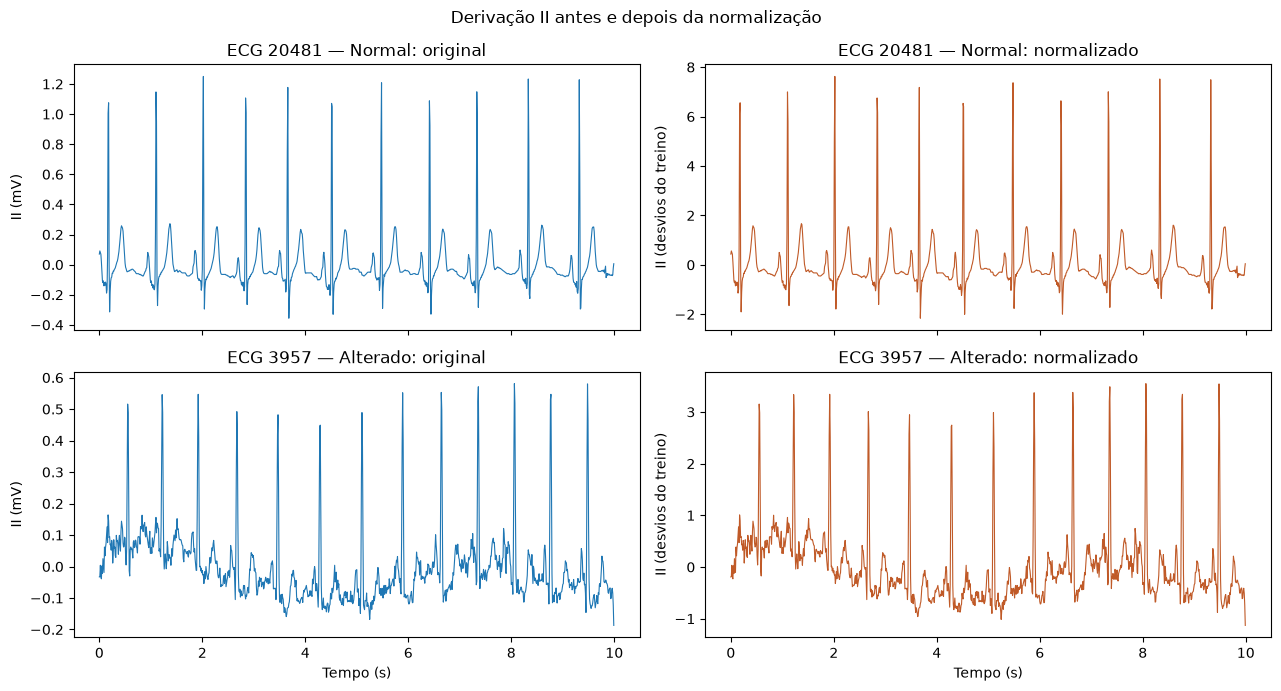

ECGs exibidos: [20481, 3957]


In [6]:
rng = np.random.default_rng(SEMENTE)
exemplos = []
for classe in (0, 1):
    candidatos = classificacao.loc[(classificacao.particao == 'treino') &
                                    (classificacao.alvo_classificacao == classe)]
    exemplos.append(candidatos.iloc[int(rng.integers(len(candidatos)))])

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
indice_ii = DERIVACOES.index('II')
for linha_grafico, exemplo in enumerate(exemplos):
    original = wfdb.rdrecord(str(DADOS / exemplo.filename_lr))
    normalizado = sinais[int(exemplo.linha_sinal)]
    tempo = np.arange(1000) / 100
    classe_texto = 'Normal' if exemplo.alvo_classificacao == 0 else 'Alterado'
    axes[linha_grafico, 0].plot(tempo, original.p_signal[:, indice_ii], lw=0.8)
    axes[linha_grafico, 1].plot(tempo, normalizado[:, indice_ii], lw=0.8, color='#c05a28')
    axes[linha_grafico, 0].set(title=f'ECG {int(exemplo.ecg_id)} — {classe_texto}: original', ylabel='II (mV)')
    axes[linha_grafico, 1].set(title=f'ECG {int(exemplo.ecg_id)} — {classe_texto}: normalizado',
                                ylabel='II (desvios do treino)')
for ax in axes[-1]: ax.set_xlabel('Tempo (s)')
fig.suptitle('Derivação II antes e depois da normalização')
fig.tight_layout()
fig.savefig(SAIDA / 'antes_depois_normalizacao.png', dpi=150)
plt.show()
print('ECGs exibidos:', [int(x.ecg_id) for x in exemplos])

## Conclusões do Pré-processamento

- **Auditoria integral:** 21.790 ECGs tinham ao menos um alvo elegível e foram lidos individualmente. Desses, 21.789 passaram. O ECG **12722** foi rejeitado das duas tarefas porque a derivação **V5 é constante**. Não houve outra rejeição de sinal. Houve **305 alertas** de amplitude absoluta ≥ 5 mV, registrados para investigação em `qualidade_sinais.csv` e mantidos nos conjuntos; o limiar não foi usado para excluir exames.
- **Classificação final:** 20.942 exames, sendo 9.069 Normal e 11.873 Alterado. Partições: **16.730 treino**, **2.105 validação**, **2.107 teste**.
- **Regressão final:** 21.505 exames com idade válida. Partições: **17.200 treino**, **2.141 validação**, **2.164 teste**. A interseção das duas tarefas contém **20.658** exames.
- **Normalização:** os 12 pares de média e desvio padrão foram ajustados com **17.411 ECGs aprovados dos folds 1–8**, na união das tarefas. Nenhum ECG dos folds 9 ou 10 contribuiu para o ajuste. A matriz final tem formato **(21.789, 1.000, 12)** e ocupa aproximadamente **0,974 GiB** em `float32`.
- **Integridade:** as validações confirmaram alvos presentes em cada tarefa, nenhuma sobreposição de pacientes entre partições, índices consistentes, dimensões corretas e ausência de NaN ou infinito na matriz final. O gráfico antes/depois mostra que a forma temporal permanece e que a escala de amplitude passa de mV para desvios do treino.

Os modelos futuros devem ler `classificacao.csv` ou `regressao.csv`, usar `linha_sinal` para acessar `sinais_normalizados.float32.bin` e preservar `particao`. `normalizacao.json` guarda os parâmetros para novos sinais. Idade e diagnósticos são alvos/metadados, **não atributos de entrada**. Nenhum modelo foi treinado nesta etapa.